CECS 381: Stochastic Computing
Unit 3 Lab: Discrete Distributions
Part A: Coding in Class (Had to do at home  
        because of projector failing).
Part B: home practice

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom, geom

rng = np.random.default_rng(381) # fixed seed: same numbers for everyone.

In [2]:
p = 0.3
N = 100_000                      # number of runs (rows)
trials = rng.random((N, 60)) < p # True = success, False = failure
# Binomial question: how many successes in the first 12 trials?
X_bin = trials[:, :12].sum(axis=1)

# Geometric question: on which trial is the first success?
# argmax finds the first True; add 1 because trial starts at 1
X_geo = trials.argmax(axis=1) + 1

print("binomial, first 5 runs: ", X_bin[:5])
print("geometric, first 5 runs: ", X_geo[:5])

binomial, first 5 runs:  [1 5 3 4 1]
geometric, first 5 runs:  [9 2 1 1 1]


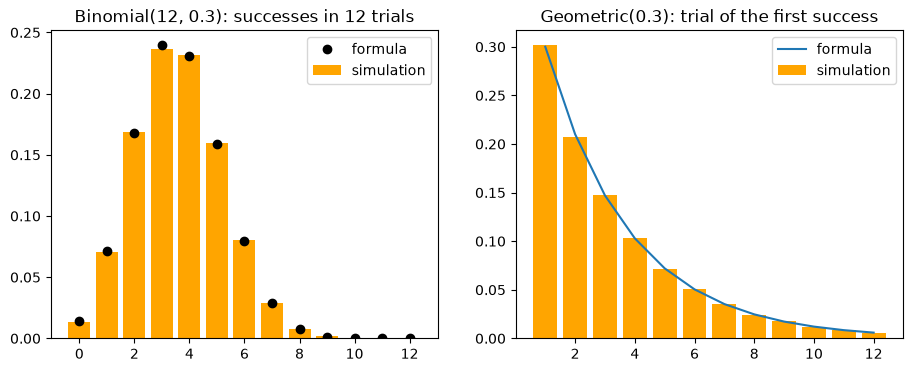

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11,4))

k = np.arange(0, 13)
sim = [np.mean(X_bin == j) for j in k]
ax[0].bar(k, sim, color="orange", label="simulation")
ax[0].plot(k, binom.pmf(k, 12, p), "ko", label = "formula")
ax[0].set_title("Binomial(12, 0.3): successes in 12 trials")

k = np.arange(1, 13)
sim = [np.mean(X_geo == j) for j in k]
ax[1].bar(k, sim, color="orange", label="simulation")
ax[1].plot(k, geom.pmf(k, p), label="formula")
ax[1].set_title("Geometric(0.3): trial of the first success")

ax[0].legend(); ax[1].legend()
plt.show()


The tail P(X > k) is the chance that the first k trials all fail. That is the same event as “no success inthe first k trials”. Check it on the same rows.

What to see:the first two columns are identical, not just close, because they count the same event.Both are close to the for

In [10]:
print("k    P(X>k)     no success   (1-p)^k")
for k in [1, 2, 3, 5, 8]:
   # the first success comes after trial k
   tail = np.mean(X_geo > k)
   # zero successes in the first k trials
   none = np.mean(trials[:, :k].sum(axis=1) == 0)
   print(f"{k}    {tail:.4f}     {none:.4f}       {(1-p)**k:.4f}")

k    P(X>k)     no success   (1-p)^k
1    0.6982     0.6982       0.7000
2    0.4908     0.4908       0.4900
3    0.3428     0.3428       0.3430
5    0.1680     0.1680       0.1681
8    0.0575     0.0575       0.0576


Each transmission gets through with probability p = 0.8. How many transmissions should we allow so that at least 99.9% of packets get through? We need P(X > k) = (1−p) k ≤ 0.001.

What to see: the search, the log formula, and SciPy all give 5

In [13]:
p = 0.8
target = 0.999

# Method 1: search k = 1, 2, 3 ... until the tail is enough
k = 1
while (1 - p)**k > 1 - target:
   k += 1
print("search :", k)

# Method 2: logarithms, then round up
print("formula:", math.ceil(math.log(1 - target)/ math.log(1-p)))

# Method 3: SciPy's inverse CDF
print("SciPy  :", int(geom.ppf(target, p)))

search : 5
formula: 5
SciPy  : 5


Check the answer by simulation.rng.geometriccounts trials and starts at 1, the same convention as our slides.

What to see:allowing 4 transmissions falls short of 99.9%; allowing 5 meets it.

In [14]:
# transmissions needed by each of 1,000,000 packets
sends = rng.geometric(p, 1_000_000)
for k in [3, 4, 5, 6]:
   ok = np.mean(sends <= k)
   print(f"allow {k} transmissions: {ok:.5f} of packets get through")

allow 3 transmissions: 0.99193 of packets get through
allow 4 transmissions: 0.99838 of packets get through
allow 5 transmissions: 0.99969 of packets get through
allow 6 transmissions: 0.99994 of packets get through


Part B: Is it Memoryless?  